# Problem Set 3 — Solutions

**OE 754/854 — Ocean Waves & Tides**

Topics: kinematics, pressure, energy, group velocity.

Released after the PS3 submission deadline. Homework is graded on submission only, so nothing here is a rubric. Compare it with what you wrote. Whatever differs is what to review before the exams. Each derivation below is followed by a short numerical check. Run the notebook top to bottom. Keep `solutions/` and `notebooks/` as sibling directories so the shared figure style imports.

Companion notebooks: `week05_airy_dispersion.ipynb` (the Newton dispersion solver used throughout), `week06_kinematics_pressure.ipynb` (orbits and the pressure response factor), and `week07_energy_groupvel.ipynb` (energy and group velocity).


In [1]:
import sys
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt
import figure_style as fs

g = 9.81
rho = 1000.0

## Problem 1. Particle orbits in three regimes.

**(a) Dispersion and regime.** Solving $\omega^2 = gk\tanh kh$ for each case:

| Case | $H$ (m) | $T$ (s) | $h$ (m) | $k$ (1/m) | $L$ (m) | $kh$ | regime |
|---|---:|---:|---:|---:|---:|---:|---|
| Deep | 2.0 | 10 | 80 | 0.04037 | 155.64 | 3.230 | deep ($kh > \pi$) |
| Intermediate | 1.0 | 6 | 5 | 0.16496 | 38.09 | 0.825 | intermediate |
| Shallow | 0.5 | 20 | 3 | 0.05820 | 107.95 | 0.175 | shallow ($kh < \pi/10$) |

The deep case is only just deep ($kh = 3.23$ against a cutoff of $\pi = 3.14$). The shallow case is only just shallow ($0.175$ against $0.314$). So solve the full dispersion relation for both instead of using the limiting forms.

**(b) Semi-axes.** With $A(z) = \frac{H}{2}\cosh k(h+z)/\sinh kh$ and $B(z) = \frac{H}{2}\sinh k(h+z)/\sinh kh$:

| Case | $z$ | $A$ (m) | $B$ (m) | $A/B$ |
|---|---|---:|---:|---:|
| Deep | $0$ | 1.0031 | 1.0000 | 1.003 |
| | $-h/2$ | 0.2071 | 0.1914 | 1.082 |
| | $-h$ | 0.0793 | 0 | $\infty$ |
| Intermediate | $0$ | 0.7378 | 0.5000 | 1.476 |
| | $-h/2$ | 0.5894 | 0.2302 | 2.561 |
| | $-h$ | 0.5426 | 0 | $\infty$ |
| Shallow | $0$ | 1.4463 | 0.2500 | 5.785 |
| | $-h/2$ | 1.4300 | 0.1245 | 11.483 |
| | $-h$ | 1.4245 | 0 | $\infty$ |

The deep orbits are circles to a third of a percent at the surface. The shallow orbits are flat: $A/B = 5.8$ at the surface and growing downward. $A$ barely changes with depth (1.446 to 1.425 over the whole column, a 1.5% variation). The intermediate case is the only one where both axes vary appreciably.

$B(-h) = 0$ in all three since $\sinh(0) = 0$. This is the bottom boundary condition: no flow through the bed, so no vertical parcel excursion there. But $A(-h) \neq 0$. The water still slides back and forth along the bed, and that motion stirs sediment.

**(c) Velocities and the breaking connection.** $u_{\max} = \omega A$:

| Case | $u_{\max}(0)$ (m/s) | $u_{\max}(-h)$ (m/s) | $C$ (m/s) | $u_{\max}(0)/C$ |
|---|---:|---:|---:|---:|
| Deep | 0.630 | 0.050 | 15.56 | 0.040 |
| Intermediate | 0.773 | 0.568 | 6.35 | 0.122 |
| Shallow | 0.454 | 0.448 | 5.40 | 0.084 |

The deep-water bed velocity is 8% of the surface value: nothing reaches the bottom. In the shallow case the bed sees 99% of the surface velocity. So shallow water moves sand and deep water does not.

The ratio $u_{\max}/C$ is the breaking diagnostic. A wave breaks when the water at the crest moves as fast as the crest itself ($u_{\max} \to C$). The particle then outruns the wave form and the surface overturns. All three cases here are at 4 to 12%, well short of breaking. The criterion is *kinematic*. Linear theory produced these numbers, and linear theory stops working as the ratio approaches 1. In practice we use the 0.78 depth criterion of Week 9.

**(d) Shallow-water limit.** As $kh \to 0$, $\cosh k(h+z) \to 1$ and $\sinh kh \to kh$, so

$$
A(z) \to \frac{H}{2}\cdot\frac{1}{kh} = \frac{H}{2kh},
$$

independent of $z$. For the shallow case, $H/(2kh) = 0.5/(2\times0.1746) = 1.432$ m. The computed values are $A(0) = 1.446$ and $A(-h) = 1.425$. The limit sits between them, 1% away from each. That is the accuracy of the shallow-water approximation at $kh = 0.175$.

**(e) Sketch.** The code cell draws the three intermediate-case ellipses to scale: a 1.48:1 ellipse at the surface and 2.56:1 at mid-depth. At the bed the orbit is a flat horizontal line segment of half-length 0.54 m.


case             k (1/m)     L (m)       kh   C (m/s)         regime
--------------------------------------------------------------------
deep             0.04037    155.64   3.2295    15.564           deep
intermediate     0.16496     38.09   0.8248     6.348   intermediate
shallow          0.05820    107.95   0.1746     5.398        shallow

case             z (m)     A (m)     B (m)      A/B  u_max (m/s)
----------------------------------------------------------------
deep              0.00    1.0031    1.0000    1.003       0.6303
deep            -40.00    0.2071    0.1914    1.082       0.1301
deep            -80.00    0.0793    0.0000      inf       0.0498

intermediate      0.00    0.7378    0.5000    1.476       0.7726
intermediate     -2.50    0.5894    0.2302    2.561       0.6172
intermediate     -5.00    0.5426    0.0000      inf       0.5682

shallow           0.00    1.4463    0.2500    5.785       0.4544
shallow          -1.50    1.4300    0.1245   11.483       0.4492
sh

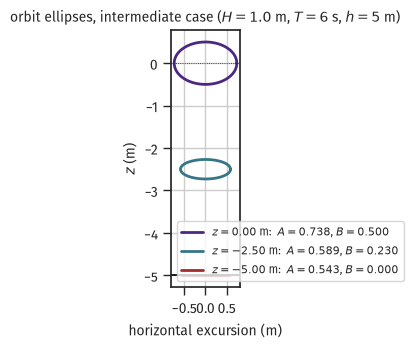

In [2]:
# Problem 1: orbit semi-axes, velocities, and the regime table
def solve_k(T, h, tol=1e-14):
    omega = 2*np.pi/T
    k = omega**2/g
    for _ in range(200):
        t = np.tanh(k*h)
        dk = (g*k*t - omega**2)/(g*t + g*k*h/np.cosh(k*h)**2)
        k -= dk
        if abs(dk) < tol:
            break
    return k


cases = [('deep', 2.0, 10.0, 80.0),
         ('intermediate', 1.0, 6.0, 5.0),
         ('shallow', 0.5, 20.0, 3.0)]

print(f'{"case":<14s}{"k (1/m)":>10s}{"L (m)":>10s}{"kh":>9s}{"C (m/s)":>10s}'
      f'{"regime":>15s}')
print('-'*68)
rows = []
for name, H, T, h in cases:
    k = solve_k(T, h)
    kh = k*h
    L = 2*np.pi/k
    C = L/T
    regime = 'deep' if kh > np.pi else ('shallow' if kh < np.pi/10 else 'intermediate')
    rows.append((name, H, T, h, k, kh, L, C))
    print(f'{name:<14s}{k:>10.5f}{L:>10.2f}{kh:>9.4f}{C:>10.3f}{regime:>15s}')

print(f'\n{"case":<14s}{"z (m)":>8s}{"A (m)":>10s}{"B (m)":>10s}{"A/B":>9s}'
      f'{"u_max (m/s)":>13s}')
print('-'*64)
for name, H, T, h, k, kh, L, C in rows:
    omega = 2*np.pi/T
    for z in (0.0, -h/2, -h):
        A = 0.5*H*np.cosh(k*(h + z))/np.sinh(kh)
        B = 0.5*H*np.sinh(k*(h + z))/np.sinh(kh)
        ratio = f'{A/B:9.3f}' if B > 1e-12 else '      inf'
        print(f'{name:<14s}{z:>8.2f}{A:>10.4f}{B:>10.4f}{ratio}{omega*A:>13.4f}')
    print()

print(f'{"case":<14s}{"u_max(0)/C":>12s}{"u_max(-h)/u_max(0)":>21s}')
print('-'*47)
for name, H, T, h, k, kh, L, C in rows:
    omega = 2*np.pi/T
    A0 = 0.5*H*np.cosh(kh)/np.sinh(kh)
    Ab = 0.5*H/np.sinh(kh)
    print(f'{name:<14s}{omega*A0/C:>12.4f}{Ab/A0:>21.4f}')

name, H, T, h, k, kh, L, C = rows[2]
print(f'\nshallow-water limit A -> H/(2kh) = {H/(2*kh):.4f} m;  '
      f'computed A(0) = {0.5*H*np.cosh(kh)/np.sinh(kh):.4f} m, '
      f'A(-h) = {0.5*H/np.sinh(kh):.4f} m')

# (e) intermediate-case ellipses, to scale
name, H, T, h, k, kh, L, C = rows[1]
th = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(fs.fullwidth*0.55, 3.6))
for i, z in enumerate((0.0, -h/2, -h)):
    A = 0.5*H*np.cosh(k*(h + z))/np.sinh(kh)
    B = 0.5*H*np.sinh(k*(h + z))/np.sinh(kh)
    ax.plot(A*np.cos(th), z + B*np.sin(th), lw=2, color=fs.color_list[i],
            label=f'$z = {z:.2f}$ m:  $A = {A:.3f}$, $B = {B:.3f}$')
ax.axhline(0, color='k', lw=0.6, ls=':')
ax.axhline(-h, color='k', lw=1.4)
ax.set_aspect('equal')
ax.set_xlabel('horizontal excursion (m)')
ax.set_ylabel('$z$ (m)')
ax.set_title(f'orbit ellipses, intermediate case ($H = {H}$ m, $T = {T:.0f}$ s, '
             f'$h = {h:.0f}$ m)')
ax.legend(fontsize=8, loc='lower left')
fig.tight_layout()
plt.show()

## Problem 2. Pressure under a wave and a bottom gauge.

**(a) $K_p(z)$ at two periods, $h = 20$ m.** With $K_p = \cosh k(h+z)/\cosh kh$:

| $z$ (m) | $K_p$, $T = 10$ s | $K_p$, $T = 4$ s |
|---:|---:|---:|
| 0 | 1.0000 | 1.0000 |
| $-2.5$ | 0.9075 | 0.5333 |
| $-5$ | 0.8303 | 0.2844 |
| $-7.5$ | 0.7670 | 0.1519 |
| $-10$ | 0.7166 | 0.0814 |
| $-12.5$ | 0.6783 | 0.0441 |
| $-15$ | 0.6514 | 0.0248 |
| $-17.5$ | 0.6354 | 0.0157 |
| $-20$ | 0.6301 | 0.0131 |

The 10-second wave ($L = 121.2$ m, $kh = 1.037$) still delivers 63% of its surface pressure signal to the bed. The 4-second wave ($L = 25.0$ m, $kh = 5.03$) delivers 1.3%, a factor of 48 less. The bed is at $z/L = -0.80$ for the short wave and $-0.16$ for the long one. In deep water $K_p \approx e^{kz}$, so the difference is $e^{-5}$ against $e^{-1}$. Depth attenuation is exponential in $z/L$ (not in $z$ alone), so period matters far more than depth.

**(b) Inverting a bottom record.** At $h = 15$ m, $T = 12$ s: $k = 0.04642$ m$^{-1}$, $L = 135.4$ m, $kh = 0.696$, and $K_p(-h) = 1/\cosh kh = 0.7985$. The dynamic pressure amplitude is $\rho g\,a\,K_p$, so

$$
a = \frac{5000}{1025\times 9.81\times 0.7985} = 0.623\ \text{m},
\qquad H = 2a = 1.25\ \text{m}.
$$

**(c) Short-period case and noise floor.** At $T = 3$ s in the same depth, $k = 0.4472$ m$^{-1}$, $kh = 6.71$, and $K_p(-h) = 0.00244$. The amplification is $1/K_p = 409$, against $1.25$ in part (b). Carrying out the inversion gives

$$
a = \frac{1000}{1025\times 9.81\times 0.00244} = 40.7\ \text{m}, \qquad H = 81\ \text{m},
$$

which is absurd. That is the answer. A 1 kPa fluctuation at 3 s in 15 m of water is not a surface wave. It is instrument noise, a boat wake, a turbulence pressure fluctuation, or a bubble on the transducer. The transfer function has multiplied it by 409. **Never apply $1/K_p$ without a cutoff.**

For the noise floor: take "usefully resolved" to mean a signal-to-noise ratio of 10 for a modest $H = 0.5$ m wave. We need $\rho g a K_p \ge 10\times 50 = 500$ Pa with $a = 0.25$ m, i.e. $K_p \ge 0.199$. In $h = 15$ m that is $T \approx 5.2$ s. For shorter periods the gauge can't tell a wave from its own noise. Standard practice: fix a cutoff frequency this way and discard the spectrum above it. If a full spectrum is needed, fill in the tail with an assumed $f^{-4}$ or $f^{-5}$ shape.

**(d) The 10% depth in deep water.** In deep water $K_p \to e^{kz}$, so $K_p = 0.1$ at

$$
kz = \ln 0.1 \quad\Longrightarrow\quad z = -\frac{\ln 10}{k} = -\frac{L\ln 10}{2\pi} = -0.366\,L .
$$

Just over a third of a wavelength. The familiar "half a wavelength and the wave is gone" rule corresponds to $K_p \approx e^{-\pi} = 0.043$, so it is a 4% rule rather than a 10% rule.

**(e) The diver.** $h = 30$ m, $T = 9$ s gives $k = 0.05379$ m$^{-1}$, $L = 116.8$ m, $kh = 1.614$; at $z = -5$ m, $K_p = 0.785$. The peak-to-peak dynamic pressure is

$$
\Delta P = 2\rho g\,\frac{H}{2}\,K_p = \rho g H K_p = 1025\times9.81\times3.0\times0.785 = 23.7\ \text{kPa},
$$

which in meters of water is $\Delta P/(\rho g) = 2.35$ m, or 78% of the wave height. So the diver's depth gauge swings by more than two meters every nine seconds, and the ears feel it. A diver working under a swell has to equalize continuously. For the same reason, bottom-mounted instruments carry a pressure-corrected depth channel instead of a raw one.


In [3]:
rho_sw = 1025.0    # seawater density (kg/m^3), per problem statement

# Problem 2: pressure response factor and bottom-gauge inversion
def Kp(z, k, h):
    return np.cosh(k*(h + z))/np.cosh(k*h)


h = 20.0
print(f'K_p(z) in h = {h:.0f} m')
print(f'{"z (m)":>8s}{"T = 10 s":>12s}{"T = 4 s":>11s}')
print('-'*31)
k10, k4 = solve_k(10.0, h), solve_k(4.0, h)
for z in np.linspace(0, -h, 9):
    print(f'{z:>8.2f}{Kp(z, k10, h):>12.4f}{Kp(z, k4, h):>11.4f}')
print(f'\nT = 10 s: L = {2*np.pi/k10:.1f} m, kh = {k10*h:.3f}, K_p(-h) = {Kp(-h, k10, h):.4f}')
print(f'T =  4 s: L = {2*np.pi/k4:.1f} m, kh = {k4*h:.3f}, K_p(-h) = {Kp(-h, k4, h):.5f}')
print(f'ratio of bed signals: {Kp(-h, k10, h)/Kp(-h, k4, h):.0f}')

# (b), (c) inverting a bottom pressure record in h = 15 m
h = 15.0
print(f'\nbottom gauge in h = {h:.0f} m')
print(f'{"T (s)":>7s}{"dp (kPa)":>11s}{"kh":>8s}{"K_p(-h)":>11s}{"1/K_p":>10s}'
      f'{"a (m)":>10s}{"H (m)":>10s}')
print('-'*67)
for T, dp in [(12.0, 5000.0), (3.0, 1000.0)]:
    k = solve_k(T, h)
    Kb = Kp(-h, k, h)
    a = dp/(rho_sw*g*Kb)
    print(f'{T:>7.1f}{dp/1e3:>11.1f}{k*h:>8.3f}{Kb:>11.5f}{1/Kb:>10.1f}'
          f'{a:>10.2f}{2*a:>10.2f}')

# noise floor: require SNR = 10 on a H = 0.5 m wave against a 50 Pa floor
from scipy.optimize import brentq
noise, snr, a_ref = 50.0, 10.0, 0.25
Kp_needed = snr*noise/(rho_sw*g*a_ref)
T_cut = brentq(lambda T: Kp(-h, solve_k(T, h), h) - Kp_needed, 2.0, 20.0)
print(f'\nrequired K_p for SNR = {snr:.0f} on a {2*a_ref:.1f} m wave: {Kp_needed:.3f}')
print(f'shortest usable period in h = {h:.0f} m: T = {T_cut:.2f} s '
      f'(f = {1/T_cut:.3f} Hz)')

# (d) 10% depth in deep water
print(f'\ndeep water: K_p = 0.1 at z/L = {-np.log(10)/(2*np.pi):.4f}')

# (e) diver
h, T, H, z = 30.0, 9.0, 3.0, -5.0
k = solve_k(T, h)
Kd = Kp(z, k, h)
dP = rho_sw*g*H*Kd
print(f'\ndiver at z = {z:.0f} m in h = {h:.0f} m, H = {H:.0f} m, T = {T:.0f} s:')
print(f'  L = {2*np.pi/k:.1f} m, kh = {k*h:.3f}, K_p = {Kd:.4f}')
print(f'  peak-to-peak dynamic pressure = {dP/1e3:.1f} kPa')
print(f'  equivalent depth swing        = {dP/(rho_sw*g):.2f} m of water '
      f'({dP/(rho_sw*g)/H:.0%} of H)')

K_p(z) in h = 20 m
   z (m)    T = 10 s    T = 4 s
-------------------------------
    0.00      1.0000     1.0000
   -2.50      0.9075     0.5333
   -5.00      0.8303     0.2844
   -7.50      0.7670     0.1519
  -10.00      0.7166     0.0814
  -12.50      0.6783     0.0441
  -15.00      0.6514     0.0248
  -17.50      0.6354     0.0157
  -20.00      0.6301     0.0131

T = 10 s: L = 121.2 m, kh = 1.037, K_p(-h) = 0.6301
T =  4 s: L = 25.0 m, kh = 5.031, K_p(-h) = 0.01307
ratio of bed signals: 48

bottom gauge in h = 15 m
  T (s)   dp (kPa)      kh    K_p(-h)     1/K_p     a (m)     H (m)
-------------------------------------------------------------------
   12.0        5.0   0.696    0.79848       1.3      0.62      1.25
    3.0        1.0   6.707    0.00244     409.1     40.69     81.38

required K_p for SNR = 10 on a 0.5 m wave: 0.199
shortest usable period in h = 15 m: T = 5.18 s (f = 0.193 Hz)

deep water: K_p = 0.1 at z/L = -0.3665

diver at z = -5 m in h = 30 m, H = 3 m, T = 9 s:

## Problem 3. Energy integration.

For the 2D Airy progressive wave

$$
\eta = \frac{H}{2}\cos(kx - \omega t), \qquad
u = \frac{H\omega}{2}\,\frac{\cosh k(h+z)}{\sinh kh}\cos(kx - \omega t), \qquad
w = \frac{H\omega}{2}\,\frac{\sinh k(h+z)}{\sinh kh}\sin(kx - \omega t),
$$

we compute the potential and kinetic energy per unit horizontal area, averaged over one wavelength.

**(a) Potential energy.** Include the whole water column first, then subtract the still-water contribution. The total PE per unit horizontal area is

$$
\mathrm{PE}_{\mathrm{tot}} = \frac{1}{L}\int_x^{x+L}\!\!\int_{-h}^{\eta}\rho g z\,dz\,dx'
= \frac{1}{L}\int_x^{x+L}\frac{\rho g}{2}\left(\eta^2 - h^2\right)dx'.
$$

Still water alone ($\eta = 0$) contributes $-\rho g h^2/2$. We want PE due to waves only:

$$
\mathrm{PE} = \frac{\rho g}{2L}\int_x^{x+L}\eta^2\,dx'
= \frac{\rho g}{2L}\cdot\frac{H^2}{4}\int_x^{x+L}\cos^2(kx' - \omega t)\,dx'.
$$

Evaluate the cosine-squared integral with the half-angle identity:

$$
\int_x^{x+L}\cos^2(kx' - \omega t)\,dx'
= \int_x^{x+L}\frac{1 + \cos 2(kx' - \omega t)}{2}\,dx' = \frac{L}{2},
$$

since $\cos 2(kx' - \omega t)$ completes two full cycles over one wavelength and integrates to zero. So

$$
\mathrm{PE} = \frac{\rho g}{2L}\cdot\frac{H^2}{4}\cdot\frac{L}{2} = \frac{1}{16}\rho g H^2. \qquad\checkmark
$$

**(b) Kinetic energy.**

$$
\mathrm{KE} = \frac{1}{L}\int_x^{x+L}\!\!\int_{-h}^{0}\frac{\rho}{2}\left(u^2 + w^2\right)dz\,dx'.
$$

(The upper limit is $z = 0$ instead of $\eta$. The sliver between them contributes at $O(H^3)$, beyond linear order.) Substituting the velocity fields,

$$
u^2 + w^2 = \frac{H^2\omega^2}{4\sinh^2 kh}\left[\cosh^2 k(h+z)\cos^2(kx' - \omega t) + \sinh^2 k(h+z)\sin^2(kx' - \omega t)\right].
$$

**Average over $x'$ first.** Both $\cos^2$ and $\sin^2$ average to $1/2$ over a full wavelength (same computation as in part a), so

$$
\frac{1}{L}\int_x^{x+L}\left(u^2 + w^2\right)dx'
= \frac{H^2\omega^2}{8\sinh^2 kh}\left[\cosh^2 k(h+z) + \sinh^2 k(h+z)\right].
$$

**Collapse the hyperbolics.** Use $\cosh^2\alpha - \sinh^2\alpha = 1$ to write $\sinh^2\alpha = \cosh^2\alpha - 1$. Then apply the double-angle formula $\cosh 2\alpha = 2\cosh^2\alpha - 1$:

$$
\cosh^2\alpha + \sinh^2\alpha = 2\cosh^2\alpha - 1 = \cosh 2\alpha.
$$

**Integrate over depth.**

$$
\int_{-h}^{0}\cosh 2k(h+z)\,dz = \left[\frac{\sinh 2k(h+z)}{2k}\right]_{-h}^{0} = \frac{\sinh 2kh}{2k}.
$$

Put it together, using $\sinh 2kh = 2\sinh kh\cosh kh$:

$$
\mathrm{KE} = \frac{\rho}{2}\cdot\frac{H^2\omega^2}{8\sinh^2 kh}\cdot\frac{\sinh 2kh}{2k}
= \frac{\rho H^2\omega^2}{32k}\cdot\frac{2\sinh kh\cosh kh}{\sinh^2 kh}
= \frac{\rho H^2\omega^2}{16\,k\tanh kh}.
$$

Now recall the dispersion relation $\omega^2 = gk\tanh kh$, so $\omega^2/(k\tanh kh) = g$:

$$
\mathrm{KE} = \frac{1}{16}\rho g H^2. \qquad\checkmark
$$

**(c) Total.** Kinetic and potential energies are equal (equipartition, characteristic of linear oscillations), and

$$
E = \mathrm{PE} + \mathrm{KE} = \frac{1}{8}\rho g H^2. \qquad\blacksquare
$$

$E$ depends only on $H$ (through $H^2$). Period and depth enter the energy *flux*, via $C_g$ (Problems 4 and 5).

In [4]:
# Quadrature check of the PE and KE integrals (T = 8 s, h = 10 m, H = 1.5 m)
T, h, H = 8.0, 10.0, 1.5
omega = 2 * np.pi / T

# Newton solve of the dispersion relation from the deep-water seed
k = omega**2 / g
for _ in range(50):
    f = g * k * np.tanh(k * h) - omega**2
    fp = g * np.tanh(k * h) + g * k * h / np.cosh(k * h) ** 2
    dk = f / fp
    k -= dk
    if abs(dk) < 1e-14:
        break
L = 2 * np.pi / k

x = np.linspace(0, L, 4001)
z = np.linspace(-h, 0, 2001)
X, Z = np.meshgrid(x, z, indexing="ij")

eta = H / 2 * np.cos(k * x)
u = H * omega / 2 * np.cosh(k * (h + Z)) / np.sinh(k * h) * np.cos(k * X)
w = H * omega / 2 * np.sinh(k * (h + Z)) / np.sinh(k * h) * np.sin(k * X)

PE = rho * g / (2 * L) * np.trapezoid(eta**2, x)
KE = rho / (2 * L) * np.trapezoid(np.trapezoid(u**2 + w**2, z, axis=1), x)

print(f"PE numeric = {PE:12.6f} J/m^2   rho g H^2/16 = {rho*g*H**2/16:12.6f}")
print(f"KE numeric = {KE:12.6f} J/m^2   rho g H^2/16 = {rho*g*H**2/16:12.6f}")
print(f"E  numeric = {PE+KE:12.6f} J/m^2   rho g H^2/8  = {rho*g*H**2/8:12.6f}")

PE numeric =  1379.531250 J/m^2   rho g H^2/16 =  1379.531250
KE numeric =  1379.531340 J/m^2   rho g H^2/16 =  1379.531250
E  numeric =  2759.062590 J/m^2   rho g H^2/8  =  2759.062500


## Problem 4. Group velocity, asymptotes.

**(a) Derive $C_g$.** Differentiate the dispersion relation $\omega^2 = gk\tanh kh$ implicitly with respect to $k$ at fixed depth $h$. Use the product rule and $\dfrac{d}{dk}\tanh kh = h\,\mathrm{sech}^2\,kh$:

$$
2\omega\,\frac{d\omega}{dk} = g\tanh kh + gkh\,\mathrm{sech}^2\,kh
\qquad\Longrightarrow\qquad
C_g \equiv \frac{d\omega}{dk} = \frac{g\tanh kh + gkh\,\mathrm{sech}^2\,kh}{2\omega}.
$$

Factor out $g\tanh kh$:

$$
C_g = \frac{g\tanh kh}{2\omega}\left[1 + \frac{kh\,\mathrm{sech}^2\,kh}{\tanh kh}\right].
$$

Simplify the two pieces separately. For the prefactor, the dispersion relation gives $g\tanh kh = \omega^2/k$, so

$$
\frac{g\tanh kh}{2\omega} = \frac{\omega}{2k} = \frac{C}{2}.
$$

For the bracket, expand $\mathrm{sech}^2\,kh = 1/\cosh^2 kh$ and $\tanh kh = \sinh kh/\cosh kh$:

$$
\frac{\mathrm{sech}^2\,kh}{\tanh kh} = \frac{1}{\cosh^2 kh}\cdot\frac{\cosh kh}{\sinh kh}
= \frac{1}{\sinh kh\cosh kh} = \frac{2}{\sinh 2kh},
$$

using $\sinh 2kh = 2\sinh kh\cosh kh$ in the last step. So

$$
C_g = \frac{C}{2}\left[1 + \frac{2kh}{\sinh 2kh}\right] = nC,
\qquad n \equiv \frac{1}{2}\left[1 + \frac{2kh}{\sinh 2kh}\right]. \qquad\blacksquare
$$

**Asymptotes.** Shallow water ($kh \ll 1$): $\sinh 2kh \approx 2kh + (2kh)^3/6$, so $2kh/\sinh 2kh \to 1$ and $n \to 1$. Energy travels with the crests: $C_g \to C \to \sqrt{gh}$. Deep water ($kh \gg 1$): $\sinh 2kh \sim e^{2kh}/2 \to \infty$, so $n \to 1/2$ and $C_g \to C/2$.

**(b) Numbers for $T = 12$ s.** Deep-water reference values: $L_0 = gT^2/2\pi = 224.8$ m, $C_0 = gT/2\pi = 18.74$ m/s. We solve the dispersion relation by Newton iteration on $f(k) = gk\tanh kh - \omega^2$, with derivative $f'(k) = g\tanh kh + gkh\,\mathrm{sech}^2\,kh$. The seed is the deep-water value $k_0 = \omega^2/g$. (Here $f'(k) = 2\omega C_g$: the Newton slope *is* the group velocity, up to a factor.) Iterates are printed below. Convergence is quadratic and reaches $|\Delta k| < 10^{-14}$ in a handful of steps.

| $h$ (m) | $kh$ | $L$ (m) | $C$ (m/s) | $C_g$ (m/s) | $n = C_g/C$ |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.383 | 82.1 | 6.84 | 6.53 | 0.954 |
| 50 | 1.534 | 204.8 | 17.07 | 10.98 | 0.643 |
| 500 | 13.973 | 224.8 | 18.74 | 9.37 | 0.500 |

**(c) Asymptote check.** At $h = 5$ m ($kh = 0.38$, upper edge of shallow), $n = 0.954 \to 1$. Both $C$ and $C_g$ sit just below $\sqrt{gh} = 7.00$ m/s. At $h = 500$ m ($kh = 14.0$, deep), $n = 0.500$ to the digit shown ($2kh/\sinh 2kh \sim 10^{-11}$). The $h = 50$ m case ($kh = 1.53$) is in the intermediate range: $n = 0.643$. $C_g$ is largest here: the bracket raises $C_g$ while $C$ has not yet dropped much. $\checkmark$

In [5]:
def newton_k(omega, h, verbose=False):
    # Solve g k tanh(kh) = omega^2 by Newton iteration from the deep-water seed
    k = omega**2 / g
    for it in range(1, 51):
        f = g * k * np.tanh(k * h) - omega**2
        fp = g * np.tanh(k * h) + g * k * h / np.cosh(k * h) ** 2
        dk = f / fp
        k -= dk
        if verbose:
            print(f"   it {it}:  k = {k:.15f} rad/m   |dk| = {abs(dk):.2e}")
        if abs(dk) < 1e-14:
            break
    return k


T = 12.0
omega = 2 * np.pi / T
print(f"L0 = {g*T**2/(2*np.pi):.1f} m,  C0 = {g*T/(2*np.pi):.2f} m/s\n")

rows = []
for h in [5.0, 50.0, 500.0]:
    print(f"h = {h:.0f} m:")
    k = newton_k(omega, h, verbose=True)
    kh = k * h
    C = omega / k
    n = 0.5 * (1 + 2 * kh / np.sinh(2 * kh))
    rows.append((h, kh, 2 * np.pi / k, C, n * C, n))

print(f"\n{'h (m)':>6} {'kh':>8} {'L (m)':>8} {'C (m/s)':>9} {'Cg (m/s)':>9} {'n':>7}")
for h, kh, L, C, Cg, n in rows:
    print(f"{h:6.0f} {kh:8.3f} {L:8.1f} {C:9.2f} {Cg:9.2f} {n:7.3f}")

print(f"\nshallow-limit speed sqrt(g h) at h = 5 m: {np.sqrt(g*5):.2f} m/s")
print(f"deep-limit n at h = 500 m: n - 1/2 = {rows[2][5] - 0.5:.2e}")

L0 = 224.8 m,  C0 = 18.74 m/s

h = 5 m:
   it 1:  k = 0.115185930762997 rad/m   |dk| = 8.72e-02
   it 2:  k = 0.081235925925836 rad/m   |dk| = 3.40e-02
   it 3:  k = 0.076657410063631 rad/m   |dk| = 4.58e-03
   it 4:  k = 0.076548140947897 rad/m   |dk| = 1.09e-04
   it 5:  k = 0.076548077104754 rad/m   |dk| = 6.38e-08
   it 6:  k = 0.076548077104732 rad/m   |dk| = 2.18e-14
   it 7:  k = 0.076548077104732 rad/m   |dk| = 0.00e+00
h = 50 m:
   it 1:  k = 0.030656615842590 rad/m   |dk| = 2.71e-03
   it 2:  k = 0.030674708862539 rad/m   |dk| = 1.81e-05
   it 3:  k = 0.030674709805243 rad/m   |dk| = 9.43e-10
   it 4:  k = 0.030674709805243 rad/m   |dk| = 4.83e-18
h = 500 m:
   it 1:  k = 0.027946552274051 rad/m   |dk| = 4.08e-14
   it 2:  k = 0.027946552274051 rad/m   |dk| = 0.00e+00

 h (m)       kh    L (m)   C (m/s)  Cg (m/s)       n
     5    0.383     82.1      6.84      6.53   0.954
    50    1.534    204.8     17.07     10.98   0.643
   500   13.973    224.8     18.74      9.37   0.50

## Problem 5. Wave power per meter of crest.

Deep-water swell, $H = 2$ m, $T = 10$ s.

**(a) Energy, group velocity, flux.** From Problem 3,

$$
E = \frac{1}{8}\rho g H^2 = \frac{(1000)(9.81)(2)^2}{8} = 4905\ \mathrm{J/m^2}.
$$

Deep water means $n = 1/2$ (Problem 4), so

$$
C_g = \frac{C_0}{2} = \frac{gT}{4\pi} = \frac{(9.81)(10)}{4\pi} = 7.81\ \mathrm{m/s}.
$$

The time-averaged energy flux per unit crest length is

$$
\mathcal{F} = E\,C_g = (4905)(7.81) = 3.83\times 10^{4}\ \mathrm{W/m} = 38.3\ \mathrm{kW/m}.
$$

**(b) Crest lengths at 100% capture.** Setting $\mathcal{F}\,\ell = P_{\mathrm{rated}}$:

$$
\ell_{\mathrm{turbine}} = \frac{10\,000\ \mathrm{kW}}{38.3\ \mathrm{kW/m}} \approx 261\ \mathrm{m},
\qquad
\ell_{\mathrm{WEC}} = \frac{100\ \mathrm{kW}}{38.3\ \mathrm{kW/m}} \approx 2.6\ \mathrm{m}.
$$

A perfect absorber spanning about two and a half meters of crest in this (energetic) sea state would match a 100 kW wave energy converter. Matching a 10 MW offshore wind turbine would take about a quarter kilometer of crest.

**(c) At 30% efficiency.** The captured flux drops to $0.3\,\mathcal{F} = 11.5$ kW/m, and the required crest lengths grow by $1/0.3$:

$$
\ell_{\mathrm{turbine}} \approx 870\ \mathrm{m},
\qquad
\ell_{\mathrm{WEC}} \approx 8.7\ \mathrm{m}.
$$

Comment: a realistic WEC needs about nine meters of absorbed crest per 100 kW, even in a healthy 2 m, 10 s swell. Smaller devices must exploit the antenna (point-absorber) effect: a resonant body draws energy from the wave field around it, so its capture width exceeds its physical width. The resource itself fluctuates with $H^2 T$, so the *rated* figure is met only in favorable seas. The crest length required, more than the physics of absorption, is the economic obstacle for wave power.

In [6]:
# Wave power numbers
H, T = 2.0, 10.0
E = rho * g * H**2 / 8
Cg = g * T / (4 * np.pi)
F = E * Cg

print(f"E  = {E:.0f} J/m^2")
print(f"Cg = {Cg:.3f} m/s")
print(f"F  = {F:.1f} W/m = {F/1e3:.2f} kW/m")
print(f"\ncrest length, 100% capture: turbine (10 MW) = {10e6/F:6.1f} m,  WEC (100 kW) = {100e3/F:5.2f} m")
print(f"crest length,  30% capture: turbine (10 MW) = {10e6/(0.3*F):6.1f} m,  WEC (100 kW) = {100e3/(0.3*F):5.2f} m")

E  = 4905 J/m^2
Cg = 7.807 m/s
F  = 38291.1 W/m = 38.29 kW/m

crest length, 100% capture: turbine (10 MW) =  261.2 m,  WEC (100 kW) =  2.61 m
crest length,  30% capture: turbine (10 MW) =  870.5 m,  WEC (100 kW) =  8.71 m


## Problem 6. Wave packet.

Two deep-water waves of equal height $H$ with $T_1 = 9.8$ s and $T_2 = 10.2$ s superpose while propagating in the $+x$ direction.

**(a) Sum-to-product.** Each component has amplitude $a = H/2$ and phase $\theta_n = k_n x - \omega_n t$. The deep-water dispersion relation gives $k_n = \omega_n^2/g = (2\pi/T_n)^2/g$. Apply the identity $\cos\theta_1 + \cos\theta_2 = 2\cos\frac{\theta_1 - \theta_2}{2}\cos\frac{\theta_1 + \theta_2}{2}$:

$$
\eta = \frac{H}{2}\cos(k_1 x - \omega_1 t) + \frac{H}{2}\cos(k_2 x - \omega_2 t)
= \underbrace{H\cos(\Delta k\,x - \Delta\omega\,t)}_{\text{slow envelope}}\;\underbrace{\cos(\bar{k}x - \bar{\omega}t)}_{\text{fast carrier}},
$$

with mean and difference wavenumbers/frequencies

$$
\bar{k} = \frac{k_1 + k_2}{2},\quad \bar{\omega} = \frac{\omega_1 + \omega_2}{2},
\qquad
\Delta k = \frac{k_1 - k_2}{2},\quad \Delta\omega = \frac{\omega_1 - \omega_2}{2}.
$$

Numerically: $\omega_1 = 0.6411$, $\omega_2 = 0.6160$ rad/s; $k_1 = 0.04190$, $k_2 = 0.03868$ rad/m; so $\bar{\omega} = 0.6286$ rad/s, $\bar{k} = 0.04029$ rad/m, $\Delta\omega = 0.01257$ rad/s, $\Delta k = 0.001611$ rad/m. Then:

- **carrier period** $2\pi/\bar{\omega} = 10.0$ s, **carrier wavelength** $2\pi/\bar{k} = 156$ m;
- **envelope period** $2\pi/\Delta\omega = 500$ s ($\approx 8.3$ min), **envelope wavelength** $2\pi/\Delta k = 3900$ m.

(One full envelope wavelength contains *two* visible groups, since the wave energy $\propto \cos^2$ repeats every half cycle of the envelope. The node-to-node group length is $\pi/\Delta k \approx 1950$ m.)

**(b) Speeds.** Carrier phase speed and envelope (group) speed:

$$
C = \frac{\bar{\omega}}{\bar{k}} = 15.60\ \mathrm{m/s},
\qquad
C_g = \frac{\Delta\omega}{\Delta k} = 7.80\ \mathrm{m/s},
\qquad
\frac{C_g}{C} = 0.500.
$$

The band is narrow, so the finite-difference ratio $\Delta\omega/\Delta k$ matches the deep-water derivative. With $\omega = \sqrt{gk}$, $\frac{d\omega}{dk} = \frac{g}{2\omega} = \frac{1}{2}\frac{\omega}{k} = \frac{C}{2}$: half the phase speed.

**(c) Carriers per envelope.**

$$
\frac{2\pi/\Delta k}{2\pi/\bar{k}} = \frac{\bar{k}}{\Delta k} = \frac{k_1 + k_2}{k_1 - k_2} \approx 25
$$

carrier wavelengths per envelope wavelength (about 12.5 crests per visible group).

**(d) Sketch.** Plotted below: $\eta(x, 0)$ over 2.5 envelope wavelengths, with the envelope $\pm H|\cos\Delta k\,x|$ overlaid. As this pattern evolves, individual crests move forward *through* the groups at $C = 2C_g$. Each crest appears at the rear node of a group, grows to full height at the antinode, and vanishes at the front node.

omega_1 = 0.6411, omega_2 = 0.6160 rad/s;  k_1 = 0.04190, k_2 = 0.03868 rad/m
carrier:  T =  10.00 s,  L =   155.9 m,  C  = 15.601 m/s
envelope: T =  499.8 s,  L =  3900.2 m,  Cg = 7.803 m/s
Cg/C = 0.5002   (deep-water g/(2 wbar) = 7.803 m/s)
carrier wavelengths per envelope wavelength: kbar/dk = 25.0


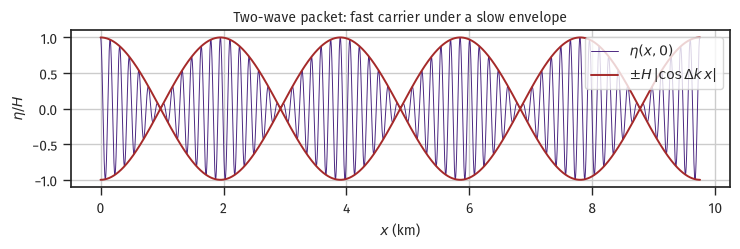

In [7]:
# Wave-packet numbers and eta(x, 0) with envelope
T1, T2, H = 9.8, 10.2, 1.0
w1, w2 = 2 * np.pi / T1, 2 * np.pi / T2
k1, k2 = w1**2 / g, w2**2 / g  # deep water
wbar, kbar = (w1 + w2) / 2, (k1 + k2) / 2
dw, dk = (w1 - w2) / 2, (k1 - k2) / 2

print(f"omega_1 = {w1:.4f}, omega_2 = {w2:.4f} rad/s;  k_1 = {k1:.5f}, k_2 = {k2:.5f} rad/m")
print(f"carrier:  T = {2*np.pi/wbar:6.2f} s,  L = {2*np.pi/kbar:7.1f} m,  C  = {wbar/kbar:.3f} m/s")
print(f"envelope: T = {2*np.pi/dw:6.1f} s,  L = {2*np.pi/dk:7.1f} m,  Cg = {dw/dk:.3f} m/s")
print(f"Cg/C = {(dw/dk)/(wbar/kbar):.4f}   (deep-water g/(2 wbar) = {g/(2*wbar):.3f} m/s)")
print(f"carrier wavelengths per envelope wavelength: kbar/dk = {kbar/dk:.1f}")

L_env = 2 * np.pi / dk
x = np.linspace(0, 2.5 * L_env, 8000)
eta = H / 2 * np.cos(k1 * x) + H / 2 * np.cos(k2 * x)
env = H * np.abs(np.cos(dk * x))

fig, ax = plt.subplots(figsize=(fs.fullwidth, 2.6))
ax.plot(x / 1e3, eta, linewidth=0.7, label=r"$\eta(x, 0)$")
ax.plot(x / 1e3, env, color=fs.color_list[2], linewidth=1.4, label=r"$\pm H\,|\cos\Delta k\,x|$")
ax.plot(x / 1e3, -env, color=fs.color_list[2], linewidth=1.4)
ax.set_xlabel("$x$ (km)")
ax.set_ylabel(r"$\eta / H$")
ax.set_title("Two-wave packet: fast carrier under a slow envelope")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## Problem 7 (Graduate students only). Energy method for group velocity.

**Claim.** A narrowband packet centered on $\omega_0$ transports its energy at $\left.\frac{d\omega}{dk}\right|_{\omega_0} = C_g$ rather than at the phase speed $C = \omega_0/k_0$.

**Step 1 — the packet.** Take the two-wave superposition of Problem 6 as the minimal packet (any narrowband packet is a superposition of such pairs):

$$
\eta = H\cos(\Delta k\,x - \Delta\omega\,t)\cos(\bar{k}x - \bar{\omega}t),
\qquad \Delta k \ll \bar{k},\ \Delta\omega \ll \bar{\omega}.
$$

**Step 2 — square to get energy density.** In linear theory the carrier-averaged total energy density per unit area is $E = \rho g\,\langle\eta^2\rangle$. With local amplitude $a$, $\langle\eta^2\rangle = a^2/2$ and $E = \rho g a^2/2$. Potential and kinetic parts contribute equally (Problem 3). So the spatial pattern of $\eta^2$ *is* the spatial pattern of energy. Square the packet:

$$
\eta^2 = H^2\cos^2(\Delta k\,x - \Delta\omega\,t)\cos^2(\bar{k}x - \bar{\omega}t).
$$

Expand both squares with $\cos^2 A = \frac{1}{2}\left(1 + \cos 2A\right)$:

$$
\eta^2 = \frac{H^2}{4}\left[1 + \cos 2(\Delta k\,x - \Delta\omega\,t)\right]\left[1 + \cos 2(\bar{k}x - \bar{\omega}t)\right].
$$

**Step 3 — average over the fast carrier.** Average over one carrier period $2\pi/\bar{\omega}$ at fixed $x$. Hold the slow factor fixed (it changes by only $O(\Delta\omega/\bar{\omega})$ over that interval). The pure carrier term $\cos 2(\bar{k}x - \bar{\omega}t)$ averages to zero. So does the slow-fast cross product. What remains is

$$
\left\langle\eta^2\right\rangle = \frac{H^2}{4}\left[1 + \cos 2(\Delta k\,x - \Delta\omega\,t)\right]
= \frac{H^2}{2}\cos^2(\Delta k\,x - \Delta\omega\,t).
$$

**Step 4 — read off the propagation speed.** The averaged energy density depends on $x$ and $t$ only through the combination

$$
\Delta k\,x - \Delta\omega\,t = \Delta k\left(x - \frac{\Delta\omega}{\Delta k}\,t\right),
$$

so the energy pattern (every antinode, every node, and the energy centroid $x_c(t) = \int x\,E\,dx \big/ \int E\,dx$ over a group) translates rigidly at

$$
\frac{\Delta\omega}{\Delta k} \;\xrightarrow{\ \Delta k \to 0\ }\; \left.\frac{d\omega}{dk}\right|_{\omega_0} = C_g. \qquad\blacksquare
$$

The carrier phase $\bar{k}x - \bar{\omega}t$ has been averaged out. The phase speed $\bar{\omega}/\bar{k}$ appears nowhere in the energy field. In deep water $\omega = \sqrt{gk}$ gives $C_g = g/2\omega = C/2$. Crests overtake the energy at twice its speed: they appear at the rear of each group and vanish at the front. The flux $\mathcal{F} = E C_g$ of Problem 5 is consistent only if energy *moves* at $C_g$. If it moved at $C$, deep-water swell would deliver twice the power measured.

**Numerical check below.** We extract the envelope of the raw two-wave $\eta(x, t)$ with a Hilbert transform and track one antinode over 300 s. We track a single carrier crest over 30 s. The measured speeds reproduce $\Delta\omega/\Delta k$ and $\bar{\omega}/\bar{k}$ to a fraction of a percent. The small residual in the crest speed is real: individual crest speeds oscillate slightly about $C$ along the group.

envelope speed, measured: 7.806 m/s   analytic dw/dk = 7.803 m/s
carrier speed,  measured: 15.588 m/s   analytic wbar/kbar = 15.601 m/s
measured ratio Cg/C = 0.5008


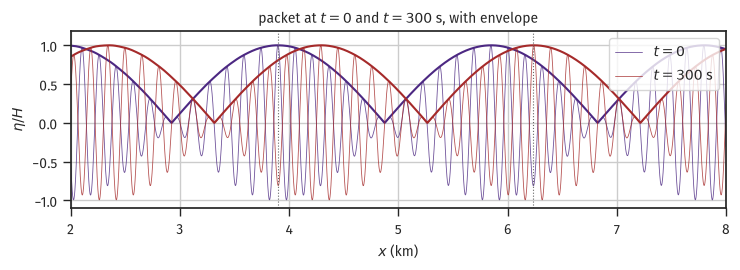

In [8]:
# Track envelope antinode (energy) and carrier crest speeds from raw eta(x, t)
from scipy.signal import hilbert

x = np.arange(0.0, 12000.0, 0.25)
dx = x[1] - x[0]


def eta_xt(t):
    return H / 2 * np.cos(k1 * x - w1 * t) + H / 2 * np.cos(k2 * x - w2 * t)


def refine_peak(y, i):
    # parabolic sub-grid refinement of a local maximum at index i
    return x[i] + dx * 0.5 * (y[i - 1] - y[i + 1]) / (y[i - 1] - 2 * y[i] + y[i + 1])


def peak_near(y, x_guess, half_width):
    m = (x > x_guess - half_width) & (x < x_guess + half_width)
    i = np.argmax(y[m]) + np.flatnonzero(m)[0]
    return refine_peak(y, i)


# Envelope antinode: Hilbert magnitude, tracked at 25 s intervals (window follows last fix)
# initial guess at the antinode dk*x = 2*pi
t_env = np.arange(0.0, 301.0, 25.0)
xe = [peak_near(np.abs(hilbert(eta_xt(0.0))), 2 * np.pi / dk, 400.0)]
for t in t_env[1:]:
    xe.append(peak_near(np.abs(hilbert(eta_xt(t))), xe[-1] + 200.0, 400.0))
xe = np.array(xe)
Cg_meas = np.polyfit(t_env, xe, 1)[0]

# Carrier crest: local max of eta itself, tracked at 0.5 s intervals near the antinode
t_car = np.arange(0.0, 30.01, 0.5)
xc = [peak_near(eta_xt(0.0), xe[0], 80.0)]
for t in t_car[1:]:
    xc.append(peak_near(eta_xt(t), xc[-1] + 8.0, 40.0))
xc = np.array(xc)
C_meas = np.polyfit(t_car, xc, 1)[0]

print(f"envelope speed, measured: {Cg_meas:.3f} m/s   analytic dw/dk = {dw/dk:.3f} m/s")
print(f"carrier speed,  measured: {C_meas:.3f} m/s   analytic wbar/kbar = {wbar/kbar:.3f} m/s")
print(f"measured ratio Cg/C = {Cg_meas/C_meas:.4f}")

# Two snapshots: the envelope advances Cg*t while crests advance C*t
t_show = 300.0
fig, ax = plt.subplots(figsize=(fs.fullwidth, 2.8))
for t, col, lab in [(0.0, fs.color_list[0], "$t = 0$"),
                    (t_show, fs.color_list[2], f"$t = {t_show:.0f}$ s")]:
    e = eta_xt(t)
    ax.plot(x / 1e3, e, color=col, linewidth=0.6, alpha=0.8, label=lab)
    ax.plot(x / 1e3, np.abs(hilbert(e)), color=col, linewidth=1.5)
ax.axvline(xe[0] / 1e3, color="0.4", linewidth=0.8, linestyle=":")
ax.axvline((xe[0] + dw / dk * t_show) / 1e3, color="0.4", linewidth=0.8, linestyle=":")
ax.set_xlim(2, 8)
ax.set_xlabel("$x$ (km)")
ax.set_ylabel(r"$\eta / H$")
ax.set_title(r"packet at $t = 0$ and $t = 300$ s, with envelope")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## Checks to remember

- Orbits go from circles in deep water to flat horizontal lines in shallow water. The vertical semi-axis $B$ vanishes at the bed in every regime (bottom boundary condition). The horizontal semi-axis does not vanish, so shallow water moves sediment.
- $u_{\max}/C$ is the kinematic breaking diagnostic. The linear theory that computes it fails as the ratio approaches 1.
- Depth attenuation of pressure is exponential in $z/L$ (not in $z$ alone). At fixed depth, halving the period can cut the bed signal by a factor of fifty. Inverting a bottom record means multiplying by $1/K_p$, so a cutoff frequency is required.

- Linear-wave energy is equipartitioned: $\mathrm{PE} = \mathrm{KE} = \frac{1}{16}\rho g H^2$. The dispersion relation supplies the final cancellation in the KE integral. The quadrature check reproduces both to discretization error.
- $n = C_g/C$ runs from 1 (shallow) to 1/2 (deep), but $C_g$ itself peaks at *intermediate* depth. That peak makes the shoaling coefficient dip below unity before it rises (see PS4).
- The Newton dispersion solve seeded with $k_0 = \omega^2/g$ converges quadratically to $|\Delta k| < 10^{-14}$ in a handful of iterations. Its slope $f'(k) = 2\omega C_g$ is the group velocity, up to a factor.
- Energy travels at $C_g$. Squaring and carrier-averaging any narrowband packet leaves a pattern that depends on space and time only through $x - (\Delta\omega/\Delta k)\,t$. The phase speed does not survive the averaging. In deep water, crests move through the groups at twice the energy speed.